In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from matplotlib.gridspec import GridSpec
import seaborn as sns


from sklearn.metrics import precision_recall_curve, average_precision_score

In [9]:
# ---------- 1. Load cleaned data ----------
df = pd.read_csv("../Dataset/AirQuality_clean.csv", parse_dates=["timestamp"])
df = df.sort_values("timestamp").reset_index(drop=True)

In [10]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor

df2 = df.copy()

# Optional: treat sensor missing code as NaN
df2 = df2.replace(-200, np.nan)

# Build target = next-hour CO
df2["target_next_co"] = df2["CO(GT)"].shift(-1)

# Keep only numeric columns for ML
X = df2.drop(columns=["CO(GT)", "target_next_co"], errors="ignore")
X = X.select_dtypes(include=[np.number])

y = df2["target_next_co"]

# Align and drop rows with NaN in X or y
data = pd.concat([X, y], axis=1).dropna()
X_train = data.iloc[:, :-1]
y_train = data.iloc[:, -1]

# Train
model = RandomForestRegressor(n_estimators=200, random_state=42)
model.fit(X_train, y_train)

# Write predictions back only on used rows
df2["co_pred"] = np.nan
df2.loc[X_train.index, "co_pred"] = model.predict(X_train)

# Residual against current CO at same rows
df2["residual"] = np.nan
df2.loc[X_train.index, "residual"] = (
    df2.loc[X_train.index, "CO(GT)"] - df2.loc[X_train.index, "co_pred"]
).abs()

threshold = df2["residual"].mean() + 3 * df2["residual"].std()
df2["anomaly"] = df2["residual"] > threshold


Threshold: 1.6944825473674097
Total rows used: 9356
Anomalies found: 223
Anomaly rate: 0.0238324249225179


,timestamp,CO(GT),co_pred,residual
27,2004-03-11 21:00:00,3.9,2.057382,1.842618
37,2004-03-12 07:00:00,1.4,3.485887,2.085887
49,2004-03-12 19:00:00,3.7,5.533464,1.833464
50,2004-03-12 20:00:00,6.6,4.517500,2.082500
53,2004-03-12 23:00:00,5.4,3.443643,1.956357
98,2004-03-14 20:00:00,5.9,3.951000,1.949000
109,2004-03-15 07:00:00,2.2,4.769293,2.569293
111,2004-03-15 09:00:00,8.1,5.768353,2.331647
119,2004-03-15 17:00:00,2.8,4.842703,2.042703
121,2004-03-15 19:00:00,8.0,6.057852,1.942148


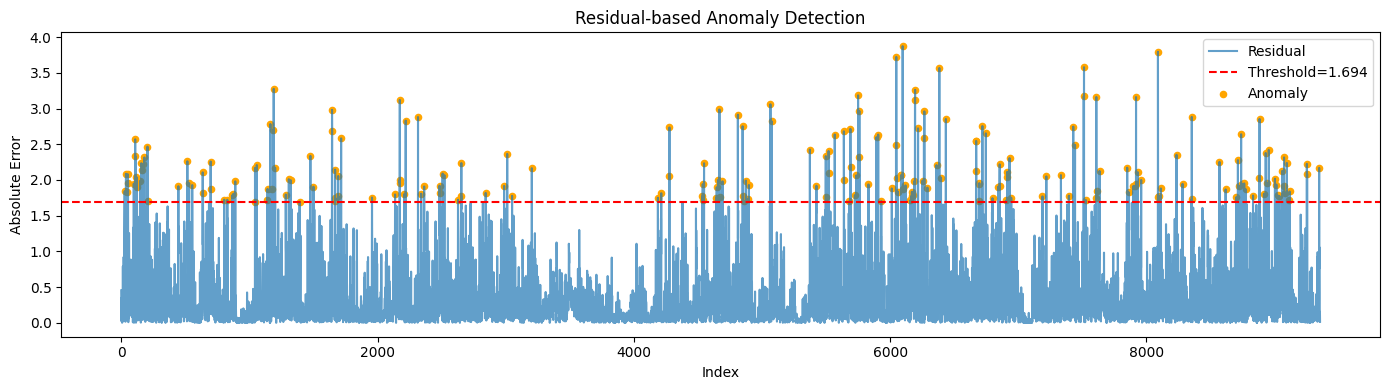

In [11]:
# 1) Quick summary
print("Threshold:", threshold)
print("Total rows used:", df2["residual"].notna().sum())
print("Anomalies found:", df2["anomaly"].sum())
print("Anomaly rate:", df2["anomaly"].mean())

# 2) Show anomaly rows
anoms = df2[df2["anomaly"] == True].copy()
display(anoms[["timestamp", "CO(GT)", "co_pred", "residual"]].head(20))

# 3) Plot residual + threshold
import matplotlib.pyplot as plt

plt.figure(figsize=(14,4))
plt.plot(df2.index, df2["residual"], label="Residual", alpha=0.7)
plt.axhline(threshold, color="red", linestyle="--", label=f"Threshold={threshold:.3f}")
plt.scatter(df2.index[df2["anomaly"]], df2.loc[df2["anomaly"], "residual"],
            color="orange", s=20, label="Anomaly")
plt.legend()
plt.title("Residual-based Anomaly Detection")
plt.xlabel("Index")
plt.ylabel("Absolute Error")
plt.tight_layout()
plt.show()



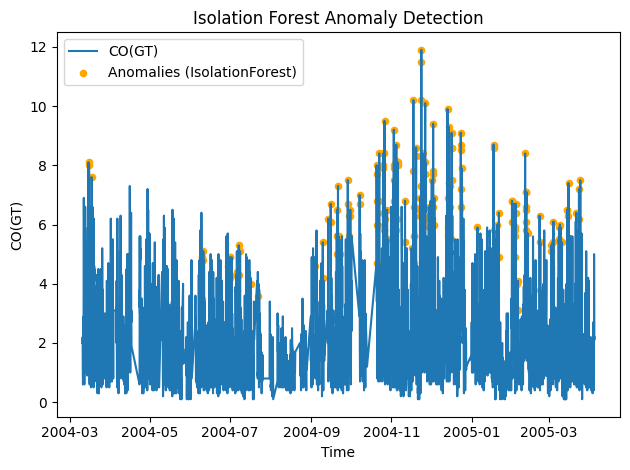

Isolation Forest anomalies detected: 188


In [12]:
# ---------- 4. Unsupervised anomaly detection (Isolation Forest) ----------
features = ["CO(GT)", "C6H6(GT)", "NOx(GT)", "NO2(GT)", "T", "RH", "AH"]
features = [f for f in features if f in df.columns]

X = df[features].ffill().bfill()

iso = IsolationForest(contamination=0.02, random_state=42)
df["anomaly_iforest"] = iso.fit_predict(X)  # -1 = anomaly, 1 = normal
target = "CO(GT)"
anomalies_iforest = df[df["anomaly_iforest"] == -1][["timestamp", target]]
anomalies_iforest["method"] = "IsolationForest"

plt.figure()
plt.plot(df["timestamp"], y, label="CO(GT)")
plt.scatter(anomalies_iforest["timestamp"], anomalies_iforest[target],
            color="orange", s=20, label="Anomalies (IsolationForest)")
plt.title("Isolation Forest Anomaly Detection")
plt.xlabel("Time"); plt.ylabel("CO(GT)")
plt.legend(); plt.tight_layout(); plt.show()

print(f"Isolation Forest anomalies detected: {len(anomalies_iforest)}")

Weekend proportion among anomalies: 0.04


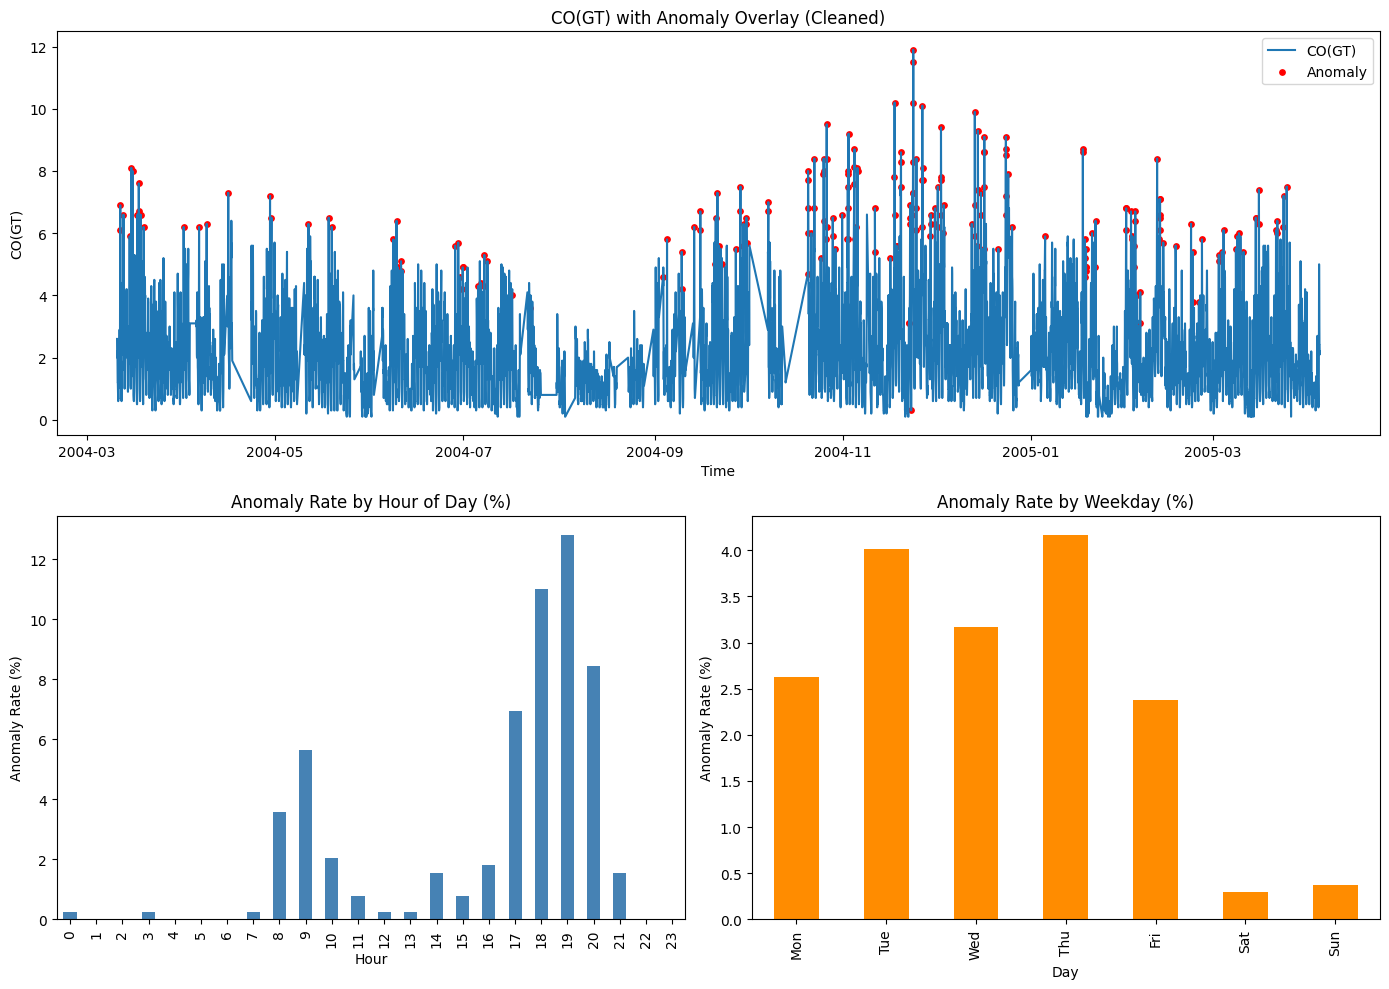

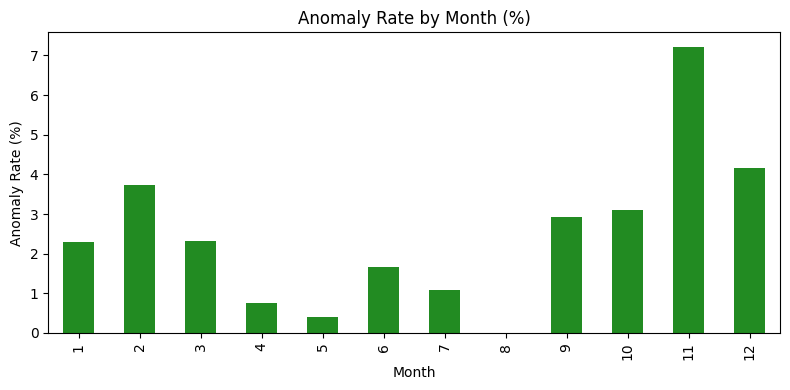

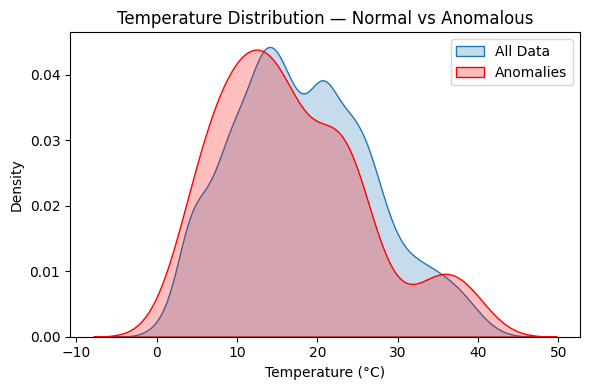

In [13]:
# ---------- 1. Load anomalies and base data ----------
df = pd.read_csv("../Dataset/AirQuality_clean.csv", parse_dates=["timestamp"])
anom = pd.read_csv("../Dataset/AirQuality_anomalies.csv", parse_dates=["timestamp"])

df["hour"] = df["timestamp"].dt.hour
df["weekday"] = df["timestamp"].dt.dayofweek
df["month"] = df["timestamp"].dt.month
df["is_weekend"] = df["weekday"].isin([5,6])

# Merge anomaly flags
df["is_anomaly"] = df["timestamp"].isin(anom["timestamp"])

# ---------- 2. Count anomalies by time dimensions ----------
hourly_anoms = df.groupby("hour")["is_anomaly"].mean() * 100
weekday_anoms = df.groupby("weekday")["is_anomaly"].mean() * 100
monthly_anoms = df.groupby("month")["is_anomaly"].mean() * 100

# ---------- 3. Overall proportions ----------
weekend_prop = df.loc[df["is_anomaly"], "is_weekend"].mean()
print(f"Weekend proportion among anomalies: {weekend_prop:.2f}")

# ---------- 4. Dashboard layout ----------
plt.figure(figsize=(14, 10))
gs = GridSpec(2, 2)

# ---- (a) Time-series overview
ax0 = plt.subplot(gs[0, :])
plt.plot(df["timestamp"], df["CO(GT)"], label="CO(GT)")
plt.scatter(df.loc[df["is_anomaly"], "timestamp"],
            df.loc[df["is_anomaly"], "CO(GT)"],
            color="red", s=15, label="Anomaly")
plt.title("CO(GT) with Anomaly Overlay (Cleaned)")
plt.xlabel("Time"); plt.ylabel("CO(GT)")
plt.legend(); plt.tight_layout(pad=2.0)

# ---- (b) Hour-of-day
ax1 = plt.subplot(gs[1, 0])
hourly_anoms.plot(kind="bar", color="steelblue")
plt.title("Anomaly Rate by Hour of Day (%)")
plt.xlabel("Hour"); plt.ylabel("Anomaly Rate (%)")

# ---- (c) Weekday pattern
ax2 = plt.subplot(gs[1, 1])
days = ["Mon","Tue","Wed","Thu","Fri","Sat","Sun"]
weekday_anoms.index = days
weekday_anoms.plot(kind="bar", color="darkorange")
plt.title("Anomaly Rate by Weekday (%)")
plt.xlabel("Day"); plt.ylabel("Anomaly Rate (%)")

plt.tight_layout()
plt.show()

# ---------- 5. Monthly distribution ----------
plt.figure(figsize=(8,4))
monthly_anoms.plot(kind="bar", color="forestgreen")
plt.title("Anomaly Rate by Month (%)")
plt.xlabel("Month"); plt.ylabel("Anomaly Rate (%)")
plt.tight_layout(); plt.show()

# ---------- 6. Temperature vs anomalies ----------
plt.figure(figsize=(6,4))
sns.kdeplot(df["T"], fill=True, label="All Data")
sns.kdeplot(df.loc[df["is_anomaly"], "T"], fill=True, label="Anomalies", color="red")
plt.title("Temperature Distribution — Normal vs Anomalous")
plt.xlabel("Temperature (°C)"); plt.legend(); plt.tight_layout(); plt.show()